# 04 — Validación formal de las hipótesis

**La pregunta.** De las cuatro hipótesis del trabajo, ¿cuáles se sostienen con un
contraste formal, con qué magnitud, y cuáles cambian la decisión del inversor?

**Qué cambia respecto de la 2da entrega.** El notebook 03 de la 2da entrega evaluó cada
hipótesis por el tamaño del efecto dentro del estrato y declaró el test que la iba a
contrastar. Acá se ejecutan esos tests. H2, que quedó como "no evaluable", se contrasta
con las distancias del notebook 01.

**La regla de este notebook.** Con 9.203 ventas casi cualquier efecto da significativo,
y el riesgo es declarar una hipótesis confirmada por un p-valor chico sobre un efecto
que no cambia ninguna decisión. Cada test cierra con cuatro cosas:

1. el p-valor y la decisión sobre H₀, con α = 0,05 fijado antes de correrlos;
2. el tamaño del efecto, en unidades que el inversor entiende (puntos de rentabilidad,
   porcentaje del precio);
3. un intervalo de confianza del 95%;
4. si ese efecto cambia o no la decisión.

Antes de cada test se verifican sus supuestos. Si una hipótesis no se sostiene tal como
fue formulada, se dice y se reformula.

| Hipótesis | Test declarado en la 2da entrega |
|---|---|
| H1 — la rentabilidad bruta cae con el precio del m² del barrio | Spearman unilateral con p-valor por permutación, repetido por tramo de superficie, con corrección por comparaciones múltiples |
| H2 — el precio del m² cae con la distancia al transporte | Regresión del precio del m² sobre la distancia, con efectos fijos de barrio |
| H3 — las unidades a reciclar cotizan con descuento | Van Elteren (Mann-Whitney estratificado por celda barrio × superficie) |
| H4 — la antigüedad pesa más en venta que en alquiler | Wald sobre la diferencia de coeficientes de dos regresiones con efectos fijos de celda, con errores por bootstrap |

Las piezas estadísticas están en `src/validacion.py` y se verifican contra scipy en
`src/test_validacion.py`. Todo se calcula en vivo.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import accesibilidad as A
import eda
import supuestos as S
import validacion as V

eda.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

P = "../data/processed"
df = pd.read_csv(f"{P}/dataset_analitico.csv", encoding="utf-8-sig", low_memory=False)
ok = df[(df["estimacion_confiable"] == 1) & df["rent_bruta_pct"].notna()].copy()
ESTRATO = ["barrio", "superficie_rango"]
N_BOOT = 5_000
alfa = S.ALFA


def p_txt(p):
    # Con permutaciones o con miles de datos, un p-valor de 1e-50 no dice mas que
    # "muy chico": se informa como cota.
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")


resumen = []
print(f"Base: {len(ok):,} ventas con estimacion confiable. Nivel de significacion: {alfa}")

Base: 9,203 ventas con estimacion confiable. Nivel de significacion: 0.05


## H1 — La rentabilidad bruta cae con el precio del m² del barrio

**La pregunta para el inversor.** ¿Comprar en un barrio más caro por m² rinde menos como
renta?

**Método.** Spearman entre el precio mediano del m² y la rentabilidad bruta mediana de
cada barrio con al menos 30 ventas. H₀: ρ = 0; H₁: ρ < 0 (unilateral). El p-valor sale
por permutación: se reparten al azar las rentabilidades entre barrios 10.000 veces y se
cuenta cuántas veces el azar da un ρ tan negativo como el observado. Se repite dentro de
cada tramo de superficie, para descartar que el efecto sea de tamaño, y esos cinco
p-valores se corrigen por Holm.

**Supuestos.** El Spearman no supone normalidad ni linealidad, solo una relación
monótona. La permutación supone que, bajo H₀, las rentabilidades son intercambiables
entre barrios. Ese supuesto se debilita si barrios vecinos se parecen por estar cerca:
el p-valor puede ser algo optimista, y por eso pesa más el tamaño del efecto.

In [2]:
g = ok.groupby("barrio").agg(n=("rent_bruta_pct", "size"), m2=("venta_m2_usd", "median"),
                             renta=("rent_bruta_pct", "median"))
b = g[g["n"] >= S.MIN_VENTAS_BARRIO]
print(f"Asimetria de las medianas barriales: precio del m2 {stats.skew(b['m2']):+.2f}, "
      f"rentabilidad {stats.skew(b['renta']):+.2f} (por eso un test de rangos)")

rho, p1 = V.permutacion_spearman(b["m2"], b["renta"], n_perm=10_000, semilla=1)
rng = np.random.default_rng(1)
boot = []
for _ in range(N_BOOT):
    i = rng.integers(0, len(b), len(b))
    boot.append(stats.spearmanr(b["m2"].values[i], b["renta"].values[i])[0])
ic_rho = np.percentile(boot, [2.5, 97.5])
ts = stats.theilslopes(b["renta"], b["m2"])
print(f"Barrios: {len(b)}. rho = {rho:+.3f}, IC 95% [{ic_rho[0]:+.3f}, {ic_rho[1]:+.3f}], "
      f"p (permutacion) = {p_txt(p1)}")
print(f"Pendiente de Theil-Sen: {ts.slope * 500:+.2f} pp de rentabilidad bruta por cada USD 500/m2 mas, "
      f"IC 95% [{ts.low_slope * 500:+.2f}, {ts.high_slope * 500:+.2f}]")

Asimetria de las medianas barriales: precio del m2 +0.31, rentabilidad +0.55 (por eso un test de rangos)


Barrios: 29. rho = -0.903, IC 95% [-0.960, -0.752], p (permutacion) = < 0,001
Pendiente de Theil-Sen: -0.98 pp de rentabilidad bruta por cada USD 500/m2 mas, IC 95% [-1.16, -0.81]


In [3]:
filas = []
for tramo in S.ORDEN_SUPERFICIE_RANGO:
    sub = ok[ok["superficie_rango"] == tramo]
    gg = sub.groupby("barrio").agg(n=("rent_bruta_pct", "size"), m2=("venta_m2_usd", "median"),
                                   renta=("rent_bruta_pct", "median"))
    gg = gg[gg["n"] >= S.MIN_AVISOS_CELDA]
    if len(gg) < 5:
        continue
    r, p = V.permutacion_spearman(gg["m2"], gg["renta"], n_perm=10_000, semilla=2)
    bt = [stats.spearmanr(*(gg[["m2", "renta"]].values[np.random.default_rng(k).integers(0, len(gg), len(gg))].T))[0]
          for k in range(2_000)]
    filas.append({"tramo (m2)": tramo, "barrios": len(gg), "rho": r,
                  "ic_inf": np.nanpercentile(bt, 2.5), "ic_sup": np.nanpercentile(bt, 97.5), "p": p})
h1 = pd.DataFrame(filas).set_index("tramo (m2)")
h1["p_holm"] = V.holm(h1["p"])
h1["rechaza H0"] = h1["p_holm"] < alfa
h1.assign(p=h1["p"].map(p_txt), p_holm=h1["p_holm"].map(p_txt))

,barrios,rho,ic_inf,ic_sup,p,p_holm,rechaza H0
tramo (m2),,,,,,,
hasta 35,25,-0.876,-0.954,-0.705,"< 0,001","< 0,001",True
36-55,29,-0.924,-0.969,-0.826,"< 0,001","< 0,001",True
56-80,29,-0.942,-0.972,-0.855,"< 0,001","< 0,001",True
81-120,28,-0.940,-0.977,-0.844,"< 0,001","< 0,001",True
120+,29,-0.949,-0.975,-0.861,"< 0,001","< 0,001",True


### Gráfico 09 — ¿La relación se sostiene comparando barrios con unidades del mismo tamaño?

Spearman entre precio del m² y rentabilidad bruta de los barrios, con todos los tamaños
juntos y dentro de cada tramo de superficie, con su intervalo de confianza del 95%.

guardado: ../graficos\09_h1_por_tramo.png


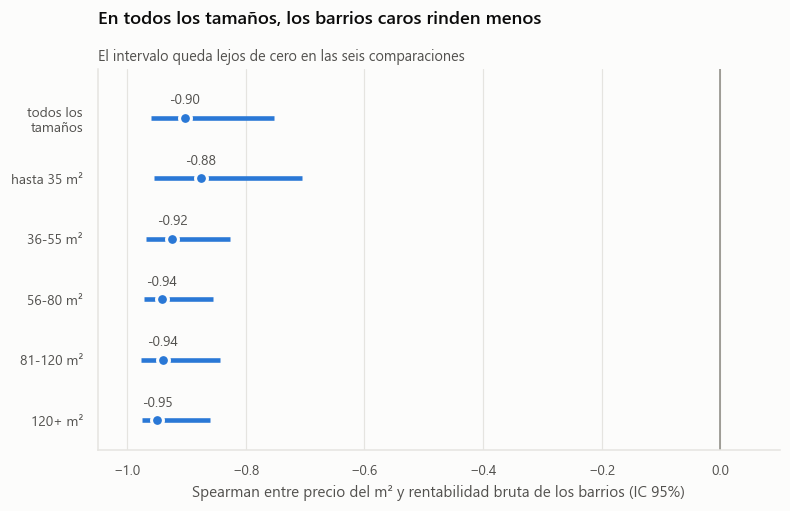

In [4]:
etiquetas = ["todos los\ntamaños"] + [f"{t} m²" for t in h1.index]
centro = [rho] + list(h1["rho"])
inf = [ic_rho[0]] + list(h1["ic_inf"])
sup = [ic_rho[1]] + list(h1["ic_sup"])

fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(centro))[::-1]
ax.hlines(yy, inf, sup, color=eda.SERIE_1, linewidth=3)
ax.scatter(centro, yy, s=60, color=eda.SERIE_1, edgecolor=eda.SUPERFICIE, linewidth=2, zorder=3)
for y_, c in zip(yy, centro):
    ax.annotate(f"{c:+.2f}", (c, y_), xytext=(0, 9), textcoords="offset points", ha="center",
                fontsize=9, color=eda.TINTA_2)
ax.axvline(0, color=eda.TINTA_3, linewidth=1)
ax.set_yticks(yy, etiquetas)
ax.set_ylim(-0.5, len(centro) - 0.2)
ax.set_xlim(-1.05, 0.1)
ax.set_xlabel("Spearman entre precio del m² y rentabilidad bruta de los barrios (IC 95%)")
eda.sin_grilla_y(ax)
eda.titulo(ax, "En todos los tamaños, los barrios caros rinden menos",
           "El intervalo queda lejos de cero en las seis comparaciones")
eda.guardar(fig, 9, "h1_por_tramo")
plt.show()

**Resultado.** Se rechaza H₀ entre barrios y en los cinco tramos de superficie, también
después de corregir por comparaciones múltiples. El efecto no es de tamaño: comparando
barrios con unidades del mismo tamaño, la correlación es igual o más fuerte.

**Magnitud.** Cada USD 500 más de precio del m² del barrio se asocia con alrededor de un
punto menos de rentabilidad bruta mediana. Entre Constitución (USD 1.129/m²) y Palermo
(USD 2.720/m²) hay unos 1.600 dólares por m²: del orden de tres puntos de rentabilidad.

**¿Cambia la decisión? Sí.** El barrio es la palanca más fuerte que tiene el inversor
sobre la rentabilidad, y en la dirección opuesta a la intuición de comprar "en el mejor
barrio". Es una relación entre barrios (medianas), no una predicción para una propiedad
puntual.

In [5]:
resumen.append({"hipotesis": "H1", "test": "Spearman, permutacion (entre barrios)",
                "p": p_txt(p1), "H0": "se rechaza" if p1 < alfa else "no se rechaza",
                "efecto": f"{ts.slope * 500:+.2f} pp de bruta por USD 500/m2",
                "IC 95%": f"[{ts.low_slope * 500:+.2f}, {ts.high_slope * 500:+.2f}]",
                "cambia la decision": "si"})

## H2 — El precio del m² cae con la distancia al transporte

**La pregunta para el inversor.** ¿Una propiedad lejos de la red se consigue más barata
que una comparable del mismo barrio?

**Método.** Regresión de log(USD/m²) sobre la distancia a la red más cercana (subte,
tren o Metrobús), con efectos fijos de barrio y los controles del notebook 01 (tipo,
superficie, antigüedad, a reciclar, amenities, cochera). H₀: la distancia no cambia el
precio; H₁: lo baja. Dos versiones, porque el notebook 01 mostró que la relación no es
lineal:

- **lineal:** un efecto por kilómetro, que es lo que declaraba la hipótesis;
- **escalón:** cuánto vale menos el m² más allá de 1 km de la red, el radio que surgió de
  la forma.

**Supuestos.** Los avisos de un mismo barrio comparten lo que no se mide (la cuadra, el
edificio), así que sus errores no son independientes. Los errores estándar se **agrupan
por barrio**: con el error común, la incertidumbre se subestima. Con 48 grupos, la
aproximación es razonable. El precio entra en logaritmo porque tiene cola larga.

In [6]:
v = df[(df["operacion"] == "venta") & df["venta_m2_usd"].notna() & df["dist_transporte_m"].notna()].copy()
v["y"] = np.log(v["venta_m2_usd"])
print(f"Asimetria del precio del m2: {stats.skew(v['venta_m2_usd']):+.2f} en dolares, "
      f"{stats.skew(v['y']):+.2f} en logaritmo")
X0 = A.matriz_base(v, controles=True)
G = v["barrio"].nunique()
q = stats.t.ppf(0.975, G - 1)


def h2_test(regresor, nombre):
    b_, se = V.ols_agrupado(np.hstack([X0, regresor]), v["y"].values, v["barrio"].values)
    t = b_[-1] / se[-1]
    return {"version": nombre, "efecto_pct": np.expm1(b_[-1]) * 100,
            "ic_inf": np.expm1(b_[-1] - q * se[-1]) * 100, "ic_sup": np.expm1(b_[-1] + q * se[-1]) * 100,
            "t": t, "p_unilateral": stats.t.cdf(t, G - 1)}


lineal = h2_test(v[["dist_transporte_m"]].values / 1000, "lineal, por km")
lejos = (v["dist_transporte_m"].values > 1000).astype(float)[:, None]
escalon = h2_test(lejos, "a mas de 1 km de la red")
h2 = pd.DataFrame([lineal, escalon]).set_index("version")
print(f"Ventas: {len(v):,}; grupos (barrios): {G}; a mas de 1 km: {int(lejos.sum())} ({lejos.mean():.1%})")
h2

Asimetria del precio del m2: +0.51 en dolares, -0.49 en logaritmo
Ventas: 10,743; grupos (barrios): 48; a mas de 1 km: 672 (6.3%)


,efecto_pct,ic_inf,ic_sup,t,p_unilateral
version,,,,,
"lineal, por km",-3.176,-7.502,1.352,-1.421,0.081
a mas de 1 km de la red,-6.675,-10.885,-2.267,-3.011,0.002


In [7]:
# Lo que se habria concluido con el error comun, sin agrupar por barrio.
b_, _ = V.ols_agrupado(np.hstack([X0, v[["dist_transporte_m"]].values / 1000]), v["y"].values, v["barrio"].values)
Xl = np.hstack([X0, v[["dist_transporte_m"]].values / 1000])
u = v["y"].values - Xl @ b_
se_comun = np.sqrt(np.linalg.pinv(Xl.T @ Xl)[-1, -1] * (u ** 2).sum() / (len(v) - Xl.shape[1]))
print(f"Pendiente lineal con error comun: t = {b_[-1] / se_comun:.2f}; con error agrupado por barrio: "
      f"t = {lineal['t']:.2f}")

D = pd.get_dummies(A.tramos(v["dist_transporte_m"]), dtype=float)
ref = D.columns[0]
b_, se = V.ols_agrupado(np.hstack([X0, D.drop(columns=ref).values]), v["y"].values, v["barrio"].values)
k = D.shape[1] - 1
perfil = pd.DataFrame({"efecto_pct": np.expm1(b_[-k:]) * 100,
                       "ic_inf": np.expm1(b_[-k:] - q * se[-k:]) * 100,
                       "ic_sup": np.expm1(b_[-k:] + q * se[-k:]) * 100,
                       "avisos": [int(D[c].sum()) for c in D.columns[1:]]},
                      index=[f"{c} m (contra {ref} m)" for c in D.columns[1:]])
perfil

Pendiente lineal con error comun: t = -4.07; con error agrupado por barrio: t = -1.42


,efecto_pct,ic_inf,ic_sup,avisos
300-600 m (contra 0-300 m),2.299,0.222,4.419,3658
"600-1,000 m (contra 0-300 m)",-0.619,-3.190,2.019,2023
"1,000-1,500 m (contra 0-300 m)",-5.963,-10.371,-1.339,512
"1,500+ m (contra 0-300 m)",-7.241,-14.708,0.879,163


**Resultado.**

- **Versión lineal: no se rechaza H₀.** El efecto por kilómetro es negativo, pero su
  intervalo incluye el cero. Con el error común habría salido muy significativo: es la
  correlación entre avisos del mismo barrio la que lo inflaba.
- **Escalón a 1 km: se rechaza H₀.** Más allá de 1 km de la red, el m² vale alrededor de
  7% menos que en avisos comparables del mismo barrio, con un intervalo que no toca el
  cero.
- **El perfil por tramos** lo confirma: el tramo de 1 a 1,5 km es significativamente más
  barato. Hasta 1 km no hay penalidad: de 300 a 600 m el m² vale incluso algo más que al
  lado de una estación (alrededor de 2%, con un intervalo que apenas excluye el cero), y
  de 600 m a 1 km no se distingue.

**H2 se reformula.** Tal como fue formulada ("el precio decrece con la distancia") no se
sostiene. La versión que los datos sostienen es: *dentro del barrio, la distancia a la
red no cambia el precio del m² hasta 1 km; más allá, el m² vale alrededor de 7% menos.*

**¿Cambia la decisión? Poco.** Para el 94% de los avisos, que está a menos de 1 km de una
estación, la cercanía no se paga: no hace falta pagar una prima por estar al lado. El
descuento lejos de la red es información para P2 en el 6% restante, pero no dice si
el alquiler cae en la misma proporción: el modelo de alquiler no usa la distancia
(notebook 03).

In [8]:
resumen.append({"hipotesis": "H2", "test": "Regresion con efectos fijos de barrio, errores agrupados",
                "p": f"lineal {p_txt(lineal['p_unilateral'])}; escalon {p_txt(escalon['p_unilateral'])}",
                "H0": ("lineal: " + ("se rechaza" if lineal["p_unilateral"] < alfa else "no se rechaza")
                       + "; escalon: " + ("se rechaza" if escalon["p_unilateral"] < alfa else "no se rechaza")),
                "efecto": f"{escalon['efecto_pct']:+.1f}% del m2 a mas de 1 km",
                "IC 95%": f"[{escalon['ic_inf']:+.1f}, {escalon['ic_sup']:+.1f}]",
                "cambia la decision": "poco (6% de los avisos)"})

## H3 — Las unidades a reciclar cotizan con descuento

**La pregunta para el inversor.** ¿Una unidad a reciclar se consigue más barata que una
comparable, y rinde más?

**Método.** Test de Van Elteren: un Mann-Whitney dentro de cada celda barrio × tramo de
superficie, combinado entre celdas. Solo compara unidades a reciclar con comparables de
su misma celda, y entra una celda si cada grupo tiene al menos 5 avisos. Dos
contrastes:

- **precio del m²:** H₀, sin diferencia; H₁, las unidades a reciclar valen menos;
- **rentabilidad bruta:** H₀, sin diferencia; H₁, rinden más.

El tamaño del efecto es la diferencia mediana dentro de la celda, ponderada por el grupo
más chico, como en la 2da entrega. Su intervalo sale por bootstrap de celdas.

**Supuestos.** Es un test de rangos: no supone normalidad, y el precio del m² es
asimétrico. Supone que dentro de cada celda los dos grupos son comparables salvo por el
estado. Tiene más potencia si el efecto va en la misma dirección en todas las celdas, y
eso se verifica.

In [9]:
ventas = df[(df["operacion"] == "venta") & df["venta_m2_usd"].notna()]
celda_v = ventas["barrio"] + " | " + ventas["superficie_rango"]
ve_p = V.van_elteren(ventas["venta_m2_usd"], ventas["a_reciclar"], celda_v, S.MIN_GRUPO_ESTRATO)
celda_k = ok["barrio"] + " | " + ok["superficie_rango"]
ve_r = V.van_elteren(ok["rent_bruta_pct"], ok["a_reciclar"], celda_k, S.MIN_GRUPO_ESTRATO)
p3_precio, p3_renta = ve_p["p_menor"], 1 - ve_r["p_menor"]


def efecto_celdas(base, col, relativo, semilla):
    t = eda.efecto_estratificado(base, "a_reciclar", col, ESTRATO, S.MIN_GRUPO_ESTRATO)
    x = (t["diferencia"] / t["mediana_0"] * 100 if relativo else t["diferencia"]).values
    w = t["peso"].values
    rng = np.random.default_rng(semilla)
    bt = [eda.mediana_ponderada(x[i], w[i]) for i in (rng.integers(0, len(t), len(t)) for _ in range(N_BOOT))]
    return eda.mediana_ponderada(x, w), np.percentile(bt, [2.5, 97.5]), (t["diferencia"] < 0).mean(), len(t)


d_p, ic_p, neg_p, c_p = efecto_celdas(ventas, "venta_m2_usd", True, 5)
d_r, ic_r, neg_r, c_r = efecto_celdas(ok, "rent_bruta_pct", False, 6)
h3 = pd.DataFrame([
    {"contraste": "precio del m2 (menor)", "celdas": ve_p["celdas"], "avisos": ve_p["avisos"], "z": ve_p["z"],
     "p": p_txt(p3_precio), "efecto": f"{d_p:+.1f}%", "IC 95%": f"[{ic_p[0]:+.1f}, {ic_p[1]:+.1f}]",
     "direccion en las celdas": f"{neg_p:.0%} mas baratas"},
    {"contraste": "rentabilidad bruta (mayor)", "celdas": ve_r["celdas"], "avisos": ve_r["avisos"], "z": ve_r["z"],
     "p": p_txt(p3_renta), "efecto": f"{d_r:+.2f} pp", "IC 95%": f"[{ic_r[0]:+.2f}, {ic_r[1]:+.2f}]",
     "direccion en las celdas": f"{1 - neg_r:.0%} rinden mas"},
]).set_index("contraste")
h3

,celdas,avisos,z,p,efecto,IC 95%,direccion en las celdas
contraste,,,,,,,
precio del m2 (menor),35,3810,-14.906,"< 0,001",-23.3%,"[-26.8, -19.2]",100% mas baratas
rentabilidad bruta (mayor),30,3628,8.312,"< 0,001",+1.12 pp,"[+0.74, +1.52]",87% rinden mas


**Resultado. Se rechaza H₀ en los dos contrastes.** Las unidades a reciclar cuestan
alrededor de 23% menos por m² que sus comparables, y el efecto va en la misma dirección en
todas las celdas. Rinden algo más de un punto más de rentabilidad bruta, también con un
intervalo lejos de cero.

**¿Cambia la decisión? Sí, pero solo junto con el costo de la obra.** El descuento por sí
solo no es una oportunidad: hay que refaccionar. El notebook 02 hizo esa cuenta. Con una
refacción mínima (baño, cocina y pintura) el descuento la cubre en el 94% de las
unidades; con una integral, en ninguna. H3 queda confirmada como descuento, y la
"oportunidad" queda condicionada al alcance de la obra.

In [10]:
resumen.append({"hipotesis": "H3", "test": "Van Elteren (barrio x superficie)",
                "p": f"precio {p_txt(p3_precio)}; renta {p_txt(p3_renta)}",
                "H0": "se rechaza" if max(p3_precio, p3_renta) < alfa else "no se rechaza en algun contraste",
                "efecto": f"{d_p:+.1f}% del m2; {d_r:+.2f} pp de bruta",
                "IC 95%": f"[{ic_p[0]:+.1f}, {ic_p[1]:+.1f}]%; [{ic_r[0]:+.2f}, {ic_r[1]:+.2f}] pp",
                "cambia la decision": "si, con refaccion minima (notebook 02)"})

## H4 — La antigüedad pesa más en el precio de venta que en el alquiler

**La pregunta para el inversor.** ¿Una unidad vieja se consigue más barata de lo que
pierde en alquiler, y por eso rinde más?

**Método.** Dos regresiones con efectos fijos de celda barrio × superficie: log(USD/m² de
venta) y log(USD/m² de alquiler) sobre la antigüedad. Con los efectos fijos, cada
coeficiente compara unidades más nuevas y más viejas de la misma celda. H₀: los dos
coeficientes son iguales; H₁: el de venta es más negativo. Test de Wald sobre la
diferencia, con el error por bootstrap: las dos muestras son independientes y de tamaño
muy distinto.

**Supuestos.** Solo antigüedad **observada**: la imputada es la mediana de su barrio y
tipo, y fabricaría una relación nula. El bootstrap remuestrea **celdas**, no avisos: los
avisos de una celda no son independientes, y remuestrear avisos achicaría el error. El
Wald usa la aproximación normal, y por eso se verifica que la distribución bootstrap
de la diferencia sea simétrica. El precio entra en logaritmo.

In [11]:
obs = df[df["antiguedad_anios_imputada"] == 0]
vv = obs[(obs["operacion"] == "venta") & obs["venta_m2_usd"].notna()]
aa = obs[(obs["operacion"] == "alquiler") & obs["alquiler_m2_usd_mes"].notna()]
print(f"Antiguedad imputada excluida: {int((df['antiguedad_anios_imputada'] == 1).sum())} avisos")
bv, boot_v, cv = V.pendiente_intra(vv["antiguedad_anios"], np.log(vv["venta_m2_usd"]),
                                   vv["barrio"] + "|" + vv["superficie_rango"], n_boot=N_BOOT, semilla=7)
ba, boot_a, ca = V.pendiente_intra(aa["antiguedad_anios"], np.log(aa["alquiler_m2_usd_mes"]),
                                   aa["barrio"] + "|" + aa["superficie_rango"], n_boot=N_BOOT, semilla=8)
dif, boot_d = bv - ba, boot_v - boot_a
z4 = dif / boot_d.std(ddof=1)
p4 = stats.norm.cdf(z4)
print(f"Asimetria de la diferencia bootstrap: {stats.skew(boot_d):+.3f} (cerca de 0: la aproximacion normal vale)")


def por_decada(x):
    # Coeficiente en log por anio -> variacion porcentual cada diez anios.
    return np.expm1(10 * np.asarray(x)) * 100


h4 = pd.DataFrame([
    {"regresion": "venta (USD/m2)", "avisos": len(vv), "celdas": cv, "efecto por decada": por_decada(bv),
     "ic_inf": por_decada(np.percentile(boot_v, 2.5)), "ic_sup": por_decada(np.percentile(boot_v, 97.5))},
    {"regresion": "alquiler (USD/m2)", "avisos": len(aa), "celdas": ca, "efecto por decada": por_decada(ba),
     "ic_inf": por_decada(np.percentile(boot_a, 2.5)), "ic_sup": por_decada(np.percentile(boot_a, 97.5))},
]).set_index("regresion")
display(h4)
print(f"Wald sobre la diferencia: z = {z4:.2f}, p unilateral = {p_txt(p4)}")
# Lo que significa para la rentabilidad: la bruta es alquiler / precio.
rel = (1 + por_decada(ba) / 100) / (1 + por_decada(bv) / 100) - 1
rel_ic = np.percentile((1 + por_decada(boot_a) / 100) / (1 + por_decada(boot_v) / 100) - 1, [2.5, 97.5])
pp = rel * ok["rent_bruta_pct"].median()
print(f"Por cada decada de antiguedad, la bruta sube {rel:+.1%} relativo "
      f"(IC 95% [{rel_ic[0]:+.1%}, {rel_ic[1]:+.1%}]): {pp:+.2f} pp sobre la bruta mediana de "
      f"{ok['rent_bruta_pct'].median():.2f}%")

Antiguedad imputada excluida: 131 avisos


Asimetria de la diferencia bootstrap: -0.063 (cerca de 0: la aproximacion normal vale)


,avisos,celdas,efecto por decada,ic_inf,ic_sup
regresion,,,,,
venta (USD/m2),10618,230,-5.716,-6.053,-5.373
alquiler (USD/m2),1348,133,-2.607,-3.364,-1.766


Wald sobre la diferencia: z = -7.12, p unilateral = < 0,001
Por cada decada de antiguedad, la bruta sube +3.3% relativo (IC 95% [+2.4%, +4.3%]): +0.23 pp sobre la bruta mediana de 7.01%


### Gráfico 10 — ¿La antigüedad abarata más la compra que el alquiler?

Variación del precio del m² por cada década de antigüedad, en venta y en alquiler,
comparando unidades de la misma celda barrio × superficie, con su intervalo del 95%.

guardado: ../graficos\10_h4_antiguedad.png


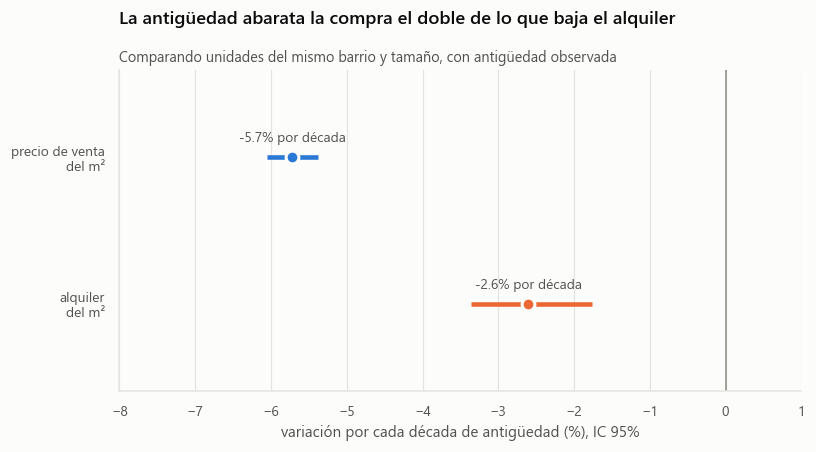

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
yy = [1, 0]
for y_, (nombre, f), color in zip(yy, h4.iterrows(), [eda.SERIE_1, eda.SERIE_2]):
    ax.hlines(y_, f["ic_inf"], f["ic_sup"], color=color, linewidth=3)
    ax.scatter(f["efecto por decada"], y_, s=70, color=color, edgecolor=eda.SUPERFICIE, linewidth=2, zorder=3)
    ax.annotate(f"{f['efecto por decada']:+.1f}% por década", (f["efecto por decada"], y_), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9, color=eda.TINTA_2)
ax.axvline(0, color=eda.TINTA_3, linewidth=1)
ax.set_yticks(yy, ["precio de venta\ndel m²", "alquiler\ndel m²"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(min(h4["ic_inf"].min() * 1.25, -8), 1)
ax.set_xlabel("variación por cada década de antigüedad (%), IC 95%")
eda.sin_grilla_y(ax)
eda.titulo(ax, "La antigüedad abarata la compra el doble de lo que baja el alquiler",
           "Comparando unidades del mismo barrio y tamaño, con antigüedad observada")
eda.guardar(fig, 10, "h4_antiguedad")
plt.show()

**Resultado. Se rechaza H₀.** Cada década de antigüedad baja el precio del m² de venta
alrededor de 5,7% y el del alquiler alrededor de 2,6%. Los intervalos no se superponen,
y la diferencia es significativa. La conclusión de la 2da entrega era tentativa por las
pocas celdas del lado del alquiler; con el contraste formal y el bootstrap por celdas
se sostiene.

**¿Cambia la decisión? Poco por sí sola.** Es el mecanismo por el que las unidades viejas
rinden más: la antigüedad abarata la compra más de lo que baja el alquiler. Por cada
década, la rentabilidad bruta sube algo más de 3% en términos relativos, unas dos
décimas de punto sobre la mediana. Una unidad de 40 años rinde, por esto solo, menos
de un punto más que una nueva: no alcanza para cruzar la banda de retorno mínimo, y el
mantenimiento de un edificio viejo no está en los gastos.

In [13]:
resumen.append({"hipotesis": "H4", "test": "Wald sobre dos regresiones con efectos fijos de celda (bootstrap por celdas)",
                "p": p_txt(p4), "H0": "se rechaza" if p4 < alfa else "no se rechaza",
                "efecto": f"venta {por_decada(bv):+.1f}% y alquiler {por_decada(ba):+.1f}% por decada; bruta {pp:+.2f} pp",
                "IC 95%": f"bruta relativa [{rel_ic[0]:+.1%}, {rel_ic[1]:+.1%}] por decada",
                "cambia la decision": "poco (menos de 1 pp en 40 anios)"})

## Resumen del notebook

La tabla se arma con los resultados de las celdas de arriba.

In [14]:
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(resumen).set_index("hipotesis"))

,test,p,H0,efecto,IC 95%,cambia la decision
hipotesis,,,,,,
H1,"Spearman, permutacion (entre barrios)","< 0,001",se rechaza,-0.98 pp de bruta por USD 500/m2,"[-1.16, -0.81]",si
H2,"Regresion con efectos fijos de barrio, errores agrupados","lineal 0,081; escalon 0,002",lineal: no se rechaza; escalon: se rechaza,-6.7% del m2 a mas de 1 km,"[-10.9, -2.3]",poco (6% de los avisos)
H3,Van Elteren (barrio x superficie),"precio < 0,001; renta < 0,001",se rechaza,-23.3% del m2; +1.12 pp de bruta,"[-26.8, -19.2]%; [+0.74, +1.52] pp","si, con refaccion minima (notebook 02)"
H4,Wald sobre dos regresiones con efectos fijos de celda (bootstrap por celdas),"< 0,001",se rechaza,venta -5.7% y alquiler -2.6% por decada; bruta +0.23 pp,"bruta relativa [+2.4%, +4.3%] por decada",poco (menos de 1 pp en 40 anios)


1. **H1 se sostiene y es la que más pesa en la decisión.** Los barrios caros rinden
   menos, en todos los tamaños: alrededor de un punto de rentabilidad bruta por cada
   USD 500/m².
2. **H2 se reformula.** El precio no cae linealmente con la distancia a la red: hasta
   1 km la distancia no se paga, y más allá el m² vale alrededor de 7% menos. Afecta al 6%
   de los avisos.
3. **H3 se sostiene como descuento**: 23% en el m² y algo más de un punto de
   rentabilidad. Es una oportunidad solo si la refacción es mínima.
4. **H4 se sostiene**: la antigüedad abarata la compra el doble de lo que baja el
   alquiler. El efecto sobre la rentabilidad es real pero chico.

**Lo que este notebook no hace:** no resuelve la decisión del inversor. Toma estas
hipótesis como insumo del notebook 06.